# 1. Classification metrics

Scores each detector against the rig ground truth and writes the
tables the other three notebooks read.

Every cell of a video is one frame of one action unit. It counts as
active in the ground truth when the Unreal Engine rig activation
exceeds the threshold, and as a detection when the detector's output
does. Comparing the two cell by cell gives the confusion counts, and
from them the true positive rate, the false positive rate and the F1
score. The AUC is computed from the detector's continuous output
against the thresholded ground truth, so it does not depend on where
the detector's own decision threshold would sit.

This notebook writes into `derivatives/au-detection-metrics/`. The
tables it writes are committed, so notebooks 2 to 4 run without it.

In [1]:
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns

from au_detection_mh import analyses, utils

DATASET = os.path.join("..", "ds-au_detection_mh")
SOURCEDATA = os.path.join(DATASET, "sourcedata")
LANDMARKS = os.path.join(DATASET, "derivatives", "landmark-displacement")
RESULTS = os.path.join(DATASET, "derivatives", "au-detection-metrics")

# Activation above which a cell of the rig ground truth counts as an
# active action unit, and above which a detector counts as reporting
# one.  0.2 is the value the reported results use.
THRESHOLD = 0.2

# Avatar order used in the figures, which groups the two avatars the
# detectors did best on next to each other.
AVATAR_ORDER = ["Ada", "Pia", "Cooper", "Garry"]

# Manuscript figure styling
LABEL_FONTSIZE = 12
TICK_FONTSIZE = 10
DPI = 500
mpl.rcParams["font.size"] = 10

## The dataset

Four MetaHuman avatars crossed with 18 animations, giving 72 videos.
The first 11 animations drive a single action unit; the remaining 7
move the brows together with another action unit.

In [2]:
print("avatars  :", utils.AVATARS)
print("animations:", utils.ANIMATIONS)
print("detectors :", utils.DETECTORS)
print("videos    :", len(utils.AVATARS) * len(utils.ANIMATIONS))

avatars  : ('Ada', 'Garry', 'Cooper', 'Pia')
animations: ('AU01', 'AU02', 'AU04', 'AU06', 'AU07', 'AU10', 'AU12', 'AU14', 'AU15', 'AU17', 'AU23', 'browsAll', 'browsAU10', 'browsAU12', 'browsAU14', 'browsAU15', 'browsAU17', 'browsAU23')
detectors : ('OF', 'AFAR', 'pyFEAT')
videos    : 72


## Ground truth and predictions, for one avatar

Each panel is frames on the x axis and action units on the y axis. The
leftmost column is what the rig did; the other three are what each
detector reported.

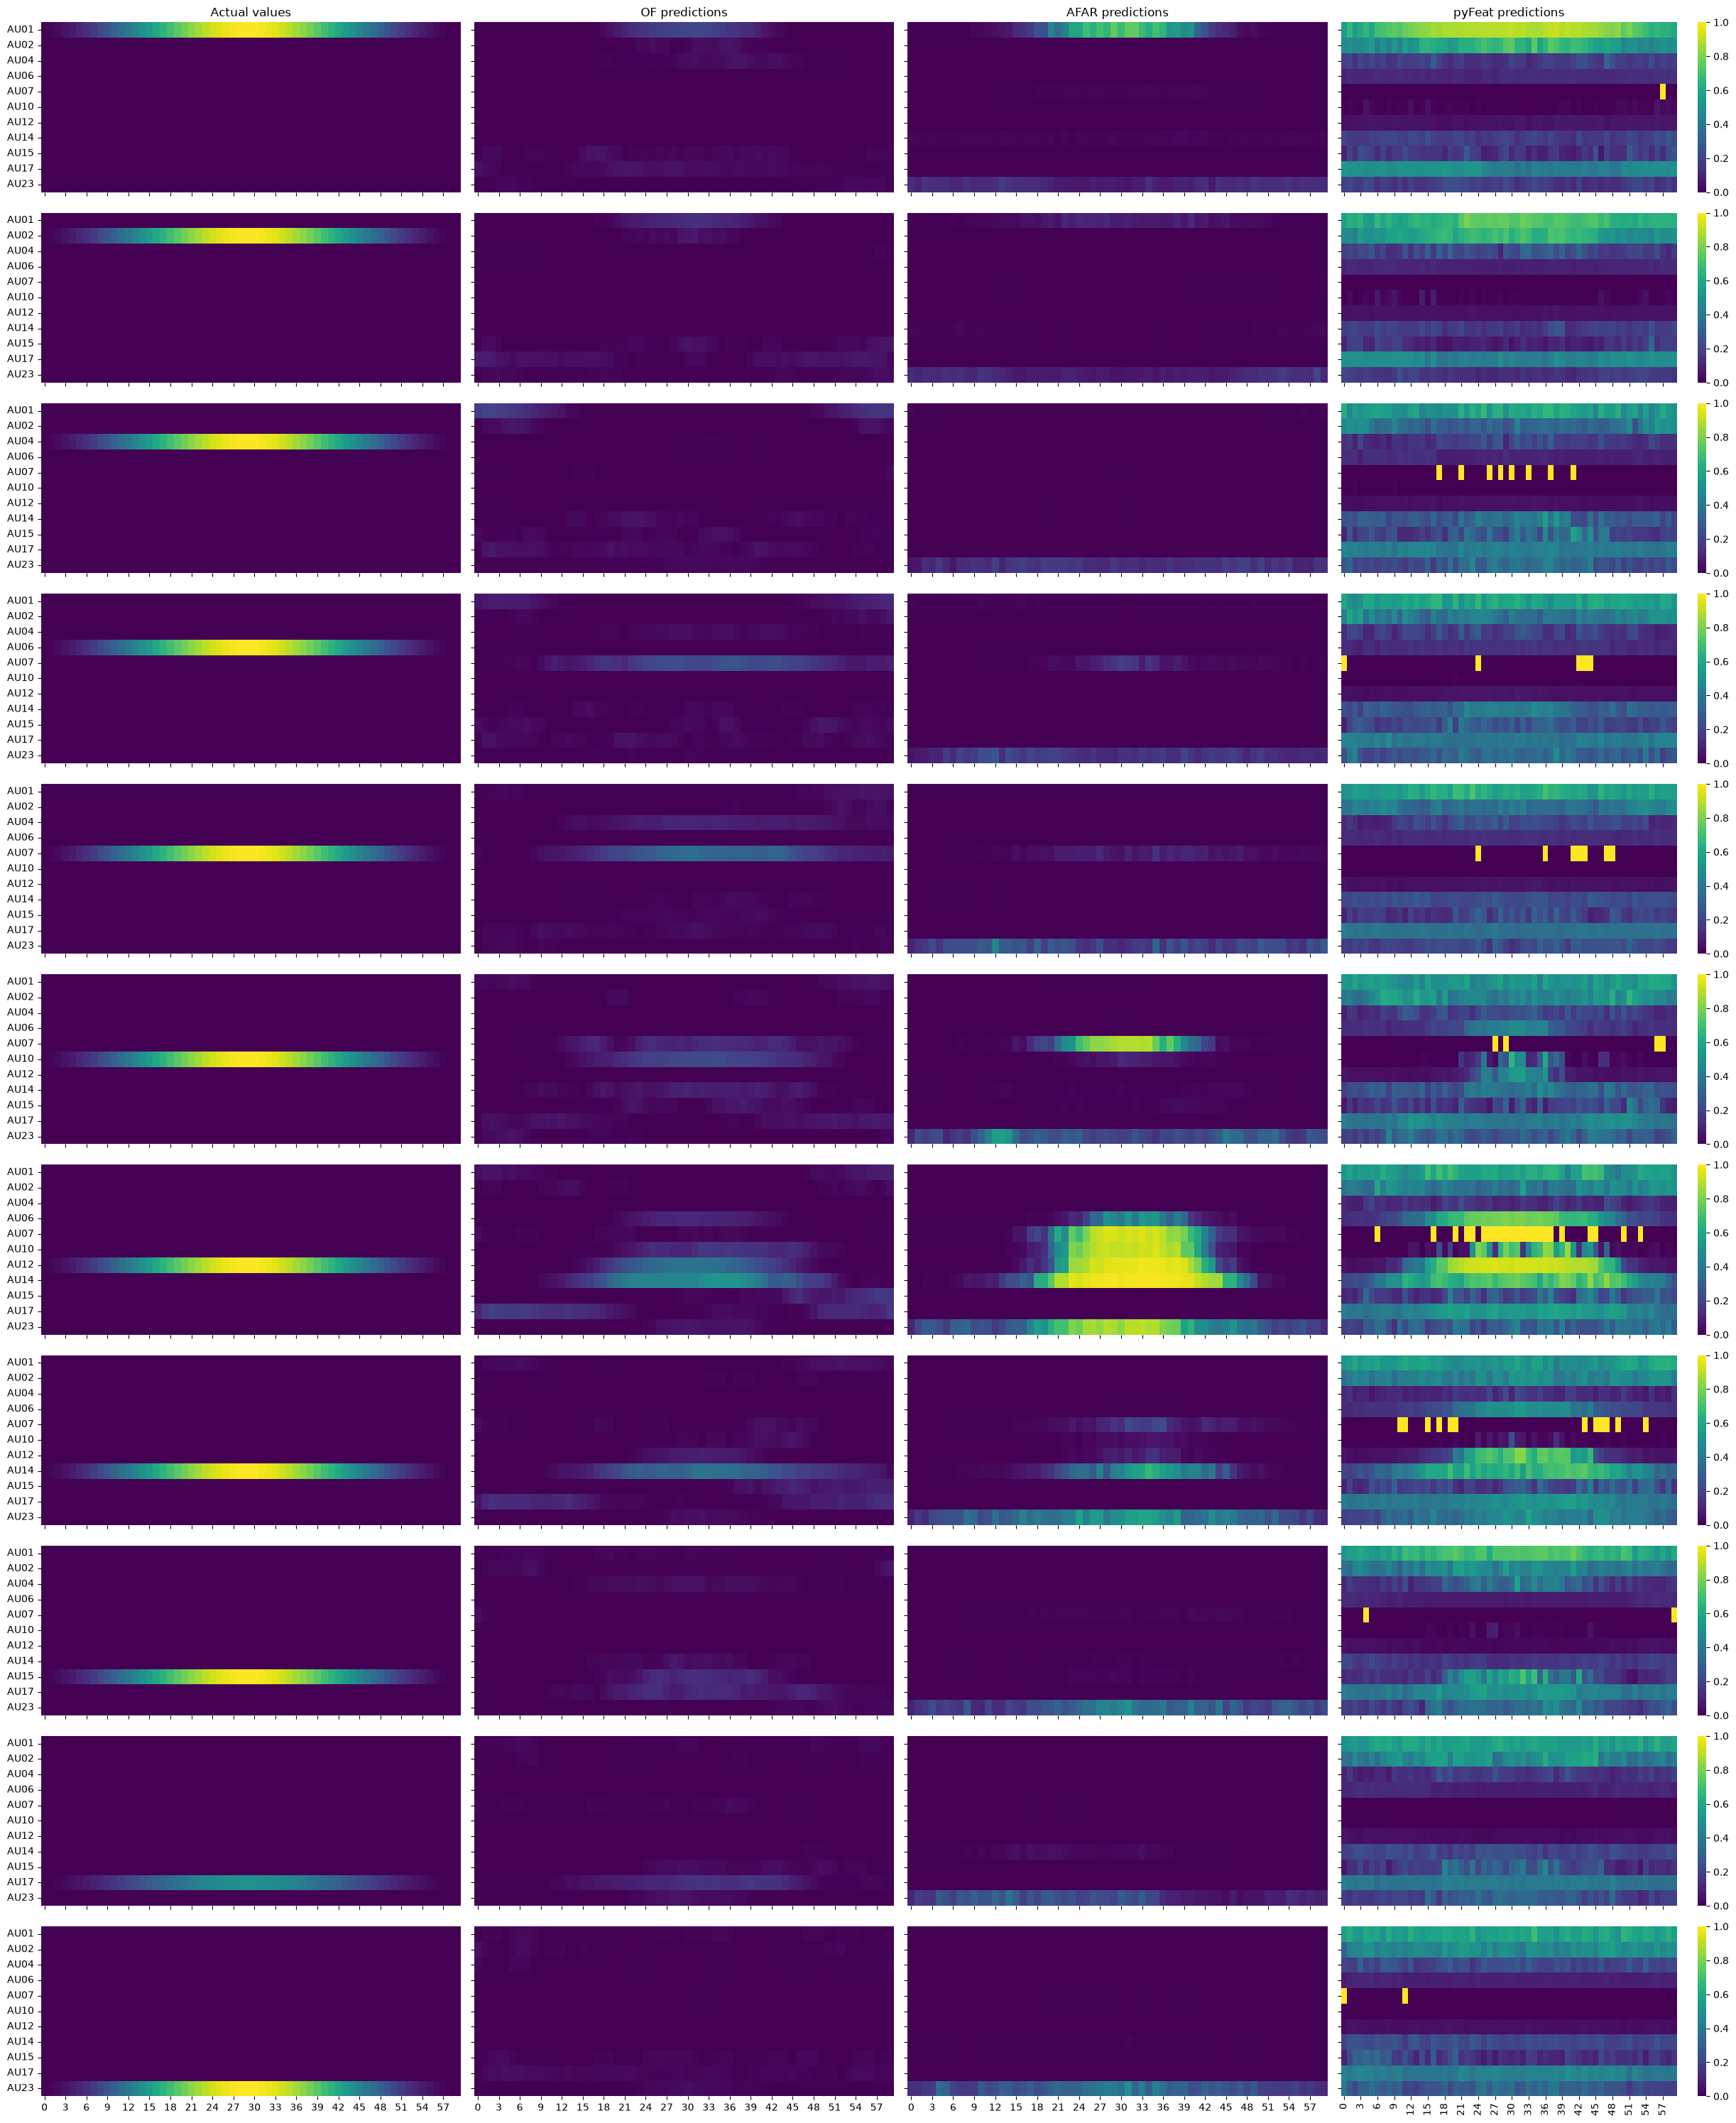

In [3]:
sns.reset_defaults()
n_rows = len(utils.AU_ONLY_ANIMATIONS)
sources = ["actual", "OF", "AFAR", "pyFEAT"]
titles = ["Actual values", "OF predictions", "AFAR predictions",
          "pyFeat predictions"]

fig, axs = plt.subplots(n_rows, len(sources), sharex=True, sharey=True,
                        figsize=(25, 30))
for row, animation in enumerate(utils.AU_ONLY_ANIMATIONS):
    video = utils.load_video(SOURCEDATA, "Ada", animation)
    for column, source in enumerate(sources):
        sns.heatmap(video[source].T, cmap="viridis", annot=False,
                    cbar=column == len(sources) - 1, vmin=0, vmax=1,
                    ax=axs[row, column])
        axs[0, column].set_title(titles[column])
        axs[row, column].set_yticks(
            np.arange(n_rows) + 0.5, labels=utils.AU_ONLY_ANIMATIONS)
        plt.setp(axs[row, column].get_yticklabels(), rotation=0,
                 ha="right", rotation_mode="anchor")
fig.tight_layout()
plt.show()

## Scoring every video

`classification_metrics_table` loops over the avatars and animations
for one detector and returns one row per video. The columns are the
confusion counts, their percentages of the matrix, which action units
the false positives fell in, the two rates, the F1 score and the AUC.

In [4]:
tables = {
    detector: analyses.classification_metrics_table(
        SOURCEDATA, detector, THRESHOLD)
    for detector in utils.DETECTORS
}
tables["OF"].head()

/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:169: UserWarning: precision is undefined: its denominator is zero
  true_positive_rate, precision(counts["TP"], counts["FP"])
/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:168: UserWarning: F1 score is undefined: sensitivity or precision is None
  row["F1_score"] = f1_score(
/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:168: UserWarning: F1 score is undefined: sensitivity and precision are both zero
  row["F1_score"] = f1_score(
/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:168: UserWarning: F1 score is undefined: sensitivity and precision are both zero
  row["F1_score"] = f1_score(
/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:169: UserWarning: precision is undefined: its denominator is zero
  true_positive_rate, precision(counts["TP"], counts["FP"])
/home/peer_herholz/code/AU_detection_MH_pr

/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:168: UserWarning: F1 score is undefined: sensitivity and precision are both zero
  row["F1_score"] = f1_score(
/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:168: UserWarning: F1 score is undefined: sensitivity and precision are both zero
  row["F1_score"] = f1_score(
/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:168: UserWarning: F1 score is undefined: sensitivity and precision are both zero
  row["F1_score"] = f1_score(
/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:168: UserWarning: F1 score is undefined: sensitivity and precision are both zero
  row["F1_score"] = f1_score(
/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/analyses.py:168: UserWarning: F1 score is undefined: sensitivity and precision are both zero
  row["F1_score"] = f1_score(
/home/peer_herholz/code/AU_detection_MH_project/au_detection_mh/a

,avatar,animation,TP,FP,TN,FN,false_detections,TP_perc,FP_perc,TN_perc,FN_perc,TPR,FPR,F1_score,AUC
0,Ada,AU01,4,0,617,39,[],1,0,93,6,0.093023,0.000000,0.170213,0.759376
1,Ada,AU02,0,0,617,43,[],0,0,93,7,0.000000,0.000000,0.000000,0.578210
2,Ada,AU04,0,1,616,43,[AU01],0,0,93,7,0.000000,0.001621,0.000000,0.415947
3,Ada,AU06,0,21,596,43,"[AU07, AU07, AU07, AU07, AU07, AU07, AU07, AU0...",0,3,90,7,0.000000,0.034036,0.000000,0.250405
4,Ada,AU07,27,0,617,16,[],4,0,93,2,0.627907,0.000000,0.771429,0.986544


In [5]:
for detector, table in tables.items():
    print(detector, table.shape)

OF (72, 15)
AFAR (72, 15)
pyFEAT (72, 15)


## Writing the tables

One file per detector, named with the threshold they were scored at, so
that a run at another threshold does not overwrite them.

In [6]:
os.makedirs(RESULTS, exist_ok=True)
for detector, table in tables.items():
    name = (f"{detector}_classification_metrics_all_"
            f"threshold_{THRESHOLD}.csv")
    table.to_csv(os.path.join(RESULTS, name))
    print("wrote", name)

wrote OF_classification_metrics_all_threshold_0.2.csv
wrote AFAR_classification_metrics_all_threshold_0.2.csv
wrote pyFEAT_classification_metrics_all_threshold_0.2.csv
